In [1]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import sqlite3

In [2]:

# 1. Import Data
conn = sqlite3.connect('C:\\Users\\Portfolio\\customer_churn.db')

sql_query = """
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
"""

tables = pd.read_sql(sql_query, conn)

# Create DataFrame for each table
for table_name in tables['name']:
    df = pd.read_sql(f"SELECT * FROM {table_name}", conn)
    globals()[f"df_{table_name}"] = df

    print(f"Created DataFrame: df_{table_name}")

conn.close()


Created DataFrame: df_db_customer
Created DataFrame: df_db_subscription
Created DataFrame: df_db_support


In [3]:
# Print table names and  column names
conn = sqlite3.connect('C:\\Users\\Portfolio\\customer_churn.db')

for table_name in tables ['name']:
    print(f"\nTable Name: {table_name}")
    # Get column information
    columns_query = f"PRAGMA table_info({table_name});"
    columns = pd.read_sql(columns_query,conn)
    print("Columns: ")
    print(columns['name'].tolist())

conn.close()


Table Name: db_customer
Columns: 
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
Columns: 
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
Columns: 
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


In [4]:
#2. data cleaning

In [5]:
df_db_customer.head()
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
16,0020-JDNXP,rikim,India,Meghalaya,Female,1994-08-19 00:00:00,NaN,None
17,0021-IKXGC,vishakha,India,Rajasthan,Female,2000-09-02 00:00:00,NaN,None
18,0022-TCJCI,raghvendra,India,Telangana,Male,1983-12-30 00:00:00,NaN,None
19,0023-HGHWL,rishabh,India,Uttar Pradesh,Men,1991-05-14 00:00:00,NaN,None
20,0023-UYUPN,sudevi,India,Maharashtra,Women,1977-10-06 00:00:00,NaN,None


In [6]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     str   
 1   name        21 non-null     str   
 2   country     18 non-null     str   
 3   state       21 non-null     str   
 4   gender      21 non-null     str   
 5   dob         21 non-null     str   
 6   interests   4 non-null      str   
 7   pincode     0 non-null      object
dtypes: object(1), str(7)
memory usage: 1.4+ KB


In [7]:
#a. rename col = name 
#b. drop columns - interest and pincode
#c. change data type
#d. data standardization - gender
#e. fix missing values

In [8]:
#a. rename col = name 

df_db_customer.rename(columns = {'name' : 'customer_name'}, inplace = True)
df_db_customer

,customerid,customer_name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None
5,0013-MHZWF,durga,NaN,Delhi,Women,1988-12-10 00:00:00,NaN,None
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21 00:00:00,NaN,None
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14 00:00:00,NaN,None
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,1985-07-07 00:00:00,NaN,None
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29 00:00:00,NaN,None


In [9]:
#b. drop columns - interest and pincode

#df_db_customer.drop(df_db_customer.columns[-2:], axis=1)
#df_db_customer.columns[-2:]

df_db_customer.drop(columns=['interests','pincode'], inplace=True)

In [10]:
df_db_customer

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00
5,0013-MHZWF,durga,NaN,Delhi,Women,1988-12-10 00:00:00
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21 00:00:00
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14 00:00:00
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,1985-07-07 00:00:00
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29 00:00:00


In [11]:
#c. change data type

df_db_customer['dob'] = pd.to_datetime(df_db_customer['dob'])

In [12]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customerid     21 non-null     str           
 1   customer_name  21 non-null     str           
 2   country        18 non-null     str           
 3   state          21 non-null     str           
 4   gender         21 non-null     str           
 5   dob            21 non-null     datetime64[us]
dtypes: datetime64[us](1), str(5)
memory usage: 1.1 KB


In [13]:
#d. data standardization - gender

#df_db_customer['gender'].unique()
df_db_customer['gender'] = df_db_customer['gender'].replace({'Men' : 'Male', 'Women' : 'Female'})


In [14]:
df_db_customer['gender'].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

In [15]:
#e. fix missing values - country

df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,NaN,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,NaN,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,NaN,Telangana,Female,2004-12-01


In [16]:
# country and state - key value pairs

state_country_mapping = df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

df_db_customer['country'] = df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [17]:
df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob


In [18]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [19]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     str    
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     str    
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      str    
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 1.9 KB


In [20]:
#]
date_col = ['subscription_start_date', 'renewal_date', 'cancellation_date']

df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 1.9 KB


In [21]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


In [22]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      str   
 1   complaint_date  9 non-null      str   
 2   escalations     9 non-null      str   
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      str   
dtypes: int64(1), object(1), str(4)
memory usage: 564.0+ bytes


In [23]:
df_db_support.drop(columns=['col_1','comment'], inplace=True)

In [24]:
df_db_support['complaint_date'] = pd.to_datetime(df_db_support['complaint_date'])

df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 420.0 bytes


In [25]:
#3. Feature Engineering and Data Analysis

In [26]:
#create a new col using existing col - churn flag
df_db_subscription['churn_flag'] = np.where(df_db_subscription['cancellation_date'].notna(), 1, 0 )

In [27]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [28]:
#first fix support table duplicates then merge

df = (df_db_subscription
        .merge(df_db_customer, on = 'customerid', how = 'left')
        .merge(df_db_support, on = 'customerid', how = 'left') )

In [29]:
df_db_subscription.shape

(21, 12)

In [30]:
df.shape

(23, 20)

In [31]:
df_db_subscription['customerid'].nunique()

21

In [32]:
df_db_customer['customerid'].nunique()

21

In [33]:
df_db_support['customerid'].nunique()

7

In [34]:
df_db_support['customerid'].size

9

In [35]:
df_db_support

,customerid,complaint_date,escalations,csat_score
0,0003-MKNFE,2024-08-28,N,60
1,0003-MKNFE,2024-08-28,Y,10
2,0013-EXCHZ,2024-01-20,Y,20
3,0013-MHZWF,2025-03-18,N,90
4,0013-SMEOE,2024-11-01,N,30
5,0017-IUDMW,2024-04-10,Y,25
6,0019-EFAEP,2024-09-27,Y,30
7,0022-TCJCI,2024-09-13,Y,10
8,0022-TCJCI,2024-09-14,N,90


In [36]:
df_db_support['complaint_count'] = df_db_support.groupby('customerid')['customerid'].transform('count')

In [37]:
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates('customerid', keep= 'last')

In [38]:
df_db_support['customerid'].size

7

In [39]:
#merge dataframe

df = (df_db_subscription
        .merge(df_db_customer, on = 'customerid', how = 'left')
        .merge(df_db_support, on = 'customerid', how = 'left') )

In [40]:
df.shape

(21, 21)

In [41]:
df.to_csv('exported_churn_data.csv', index=False)

In [42]:
# Data Analysis

In [43]:
# Churn Rate

In [44]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='str')

In [45]:
churn_rate = df['churn_flag'].mean()*100
print("Churn Rate = ", round(churn_rate,2), '%')

Churn Rate =  28.57 %


In [46]:
# 2. Retenion Rate
retention_rate = 100 - churn_rate
print("Retention Rate = ", round(retention_rate,2), '%')

Retention Rate =  71.43 %


In [47]:
df.head(2)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0


In [48]:
# 3. Chrun by Plan Type
churn_by_plan = (df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index(name='churn_rate_pct'))

print(churn_by_plan)

  plan_type  churn_rate_pct
0     Basic           60.00
1   Premium           14.29
2  Standard           22.22


In [49]:
# 4.a. Churn By State + sum(revenue) & count of users
# 4.b.Churn by subscription type + sum(revenue) & count of users

In [50]:
# 4.b.Churn by subscription type + sum(revenue) & count of users

churn_by_subscription = (
    df.groupby('subscription_type')
    .agg(
        churn_rate_subscription = ('churn_flag', lambda x: x.mean() * 100),
        total_revenue_by_subscription = ('monthly_charges', 'sum'),
        total_users_by_subscription = ('customerid', 'count')
    )
    .round(2)
    .reset_index()
)

print(churn_by_subscription)

  subscription_type  churn_rate_subscription  total_revenue_by_subscription  \
0           Organic                     0.00                         145.91   
1              Paid                    16.67                         174.94   
2          Refferal                    83.33                          74.94   

   total_users_by_subscription  
0                            9  
1                            6  
2                            6  


In [51]:
# 4.a. Churn By State + sum(revenue) & count of users

churn_by_state = (
    df.groupby('state')
    .agg(
        churn_rate_state = ('churn_flag', lambda x: x.mean() * 100),
        total_revenue_by_state = ('monthly_charges', 'sum'),
        total_users_by_state = ('customerid', 'count')
    )
    .round(2)
    .reset_index()
)

print(churn_by_state)

           state  churn_rate_state  total_revenue_by_state  \
0          Delhi             25.00                   52.96   
1      Karnataka            100.00                   20.98   
2      Kathmandu              0.00                   20.98   
3    Maharashtra              0.00                   50.97   
4      Meghalaya             66.67                   42.97   
5       Nagaland              0.00                   22.99   
6      Rajasthan              0.00                   36.98   
7      Telangana             50.00                   30.98   
8  Uttar Pradesh              0.00                  115.98   

   total_users_by_state  
0                     4  
1                     2  
2                     2  
3                     3  
4                     3  
5                     1  
6                     2  
7                     2  
8                     2  


In [52]:
# 5. ARU - Average Revenue per User

arpu = df['monthly_charges'].mean()
print('ARPU = ',round(arpu,2))

ARPU =  18.85


In [53]:
## Calculate customer age
df['dob'] = pd.to_datetime(df['dob'])

df['age'] = ((pd.Timestamp.today() - df['dob']).dt.days / 365.25).astype(int)

print(df[['dob', 'age']].head())

         dob  age
0 1982-04-12   44
1 1995-11-23   30
2 1978-02-15   48
3 2001-08-30   25
4 1990-05-05   36


In [54]:
# 6. Avg customer Tenure 
# count of days user has used our service : cancellation date else current date

today = pd.Timestamp.today()

df['tenure_days'] = np.where(
        df['cancellation_date'].notna(), 
        (df['cancellation_date'] - df['subscription_start_date']).dt.days,
        (today - df['subscription_start_date']).dt.days
)

avg_tenure = df['tenure_days'].mean()
print('Avg Tenure (Days) = ', round(avg_tenure),0)


Avg Tenure (Days) =  1584 0


In [55]:
# Revenue at risk - revenue lost from churned users
revenue_at_risk = df.loc[df['churn_flag']==1, 'monthly_charges'].sum()
print("Revenue at Risk (Rs 'K')  = ", revenue_at_risk)

Revenue at Risk (Rs 'K')  =  73.94


In [56]:
# 8. Escalation Rate 
escalation_rate = (df['escalations']=='Y').mean()*100
print('Escalation Rate = ',round(escalation_rate, 2), '%')

Escalation Rate =  19.05 %


In [57]:
# 9.Average Complaint Per User
avg_complaint = df['complaint_count'].sum() / df['customerid'].nunique()
print('Average Complaint Per User =',round(avg_complaint,2))

Average Complaint Per User = 0.43


In [58]:
print(df['escalations'].unique())

<StringArray>
[nan, 'Y', 'N']
Length: 3, dtype: str


In [59]:
#10. Correlation Escalation Vs Churn

df['escalations'] = np.where(df['escalations'] == 'Y', 1, 0)  #encoding string to int type
corr_df = df[['escalations' , 'churn_flag']].dropna()

correlation = corr_df['escalations'].corr(df['churn_flag'])
print('Correlation between escalation vs churn is = ',round(correlation,2))

Correlation between escalation vs churn is =  0.77


In [60]:
# 11. Create a column using existing risk column - Churn Risk

conditions = [
        (df['churn_score'] < 50),
        (df['churn_score'] >= 50) & (df['churn_score'] < 70),
        (df['churn_score'] >= 70),
]

choices = ['Low', 'Medium', 'High']

df['churn_risk'] = np.select(conditions, choices, default='unknown')

In [61]:
df[['churn_risk', 'churn_score']].tail()

,churn_risk,churn_score
16,Medium,62
17,Low,27
18,High,99
19,Low,7
20,Low,47


In [62]:
# 4. Visualization using Motplotlib 

In [63]:
df_visual = df.copy()

In [64]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count', 'age',
       'tenure_days', 'churn_risk'],
      dtype='str')

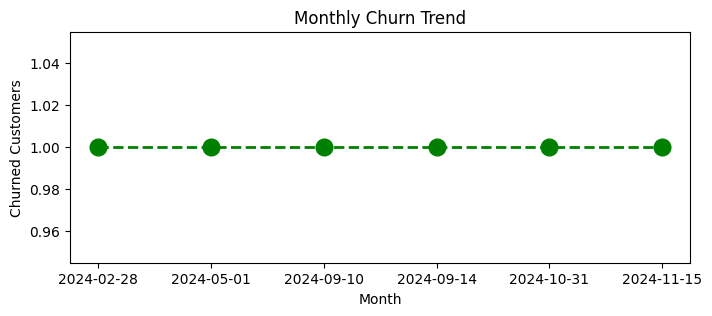

In [65]:
# 4.1 Monthly Churn Trend [Time Series KPI]

# df_visual['cancellation_date'] = df_visual['cancellation_date'].dt.to_period('M')

churn_trend = df_visual[df_visual['churn_flag'] == 1].groupby('cancellation_date').size()

plt.figure(figsize=(8,3))
plt.plot(churn_trend.index.astype(str), churn_trend.values, color='green', marker='o', linestyle='dashed', linewidth=2, markersize=12)  

plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.show()

<BarContainer object of 3 artists>

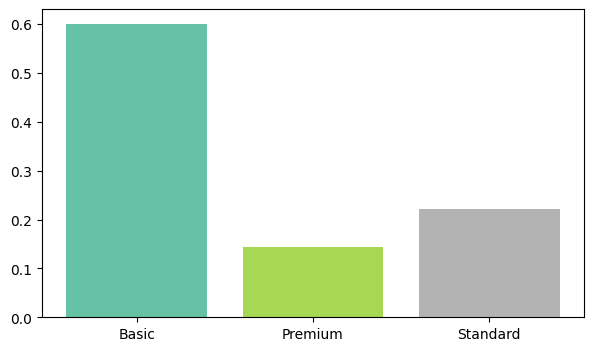

In [66]:
# 4.2 Churn by Plan Type
churn_plan = df_visual.groupby('plan_type')['churn_flag'].mean()

#colors = ['yellow' , 'purple' , 'blue']
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))
plt.figure(figsize=(7,4))

plt.bar(churn_plan.index, churn_plan.values, color = colors)

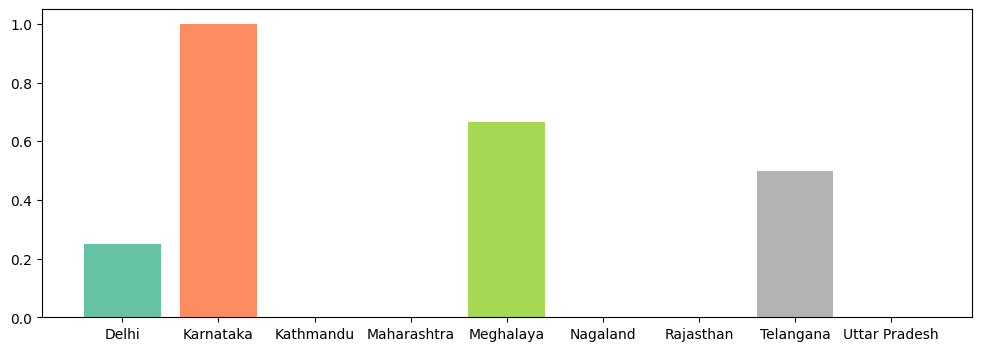

In [67]:
# 4.2 Churn by States
churn_plan = df_visual.groupby('state')['churn_flag'].mean()

#colors = ['yellow' , 'purple' , 'blue']
colors = plt.cm.Set2(np.linspace(0, 1, len(churn_plan)))
plt.figure(figsize=(12,4))

plt.bar(churn_plan.index, churn_plan.values, color = colors)
plt.show()

In [68]:
# Visualization using Seaborn

In [69]:
# Encoding - Convert string to numeric so that e can convert corr between features

df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count', 'age',
       'tenure_days', 'churn_risk'],
      dtype='str')

In [70]:
df_visual[['plan_type', 'contract_type', 'churn_score',  'churn_risk', 'escalations']].head()

,plan_type,contract_type,churn_score,churn_risk,escalations
0,Standard,Annual,12,Low,0
1,Premium,Annual,91,High,1
2,Basic,Monthly,34,Low,0
3,Premium,Annual,8,Low,0
4,Standard,Monthly,88,High,1


In [72]:
#incorrect method of encoding - as numbers are not asssigned based on priority
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_risk', 'escalations']].head()

categorial_cols = ['plan_type', 'contract_type', 'churn_risk']

for col in  categorial_cols:
    df_encoded[col] = df_encoded[col].astype('category').cat.codes

<Axes: >

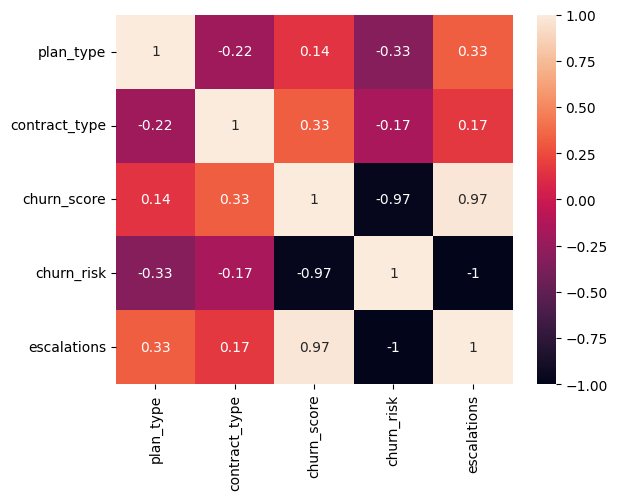

In [73]:
# Heatmap (Correlation matrix)

sns.heatmap(df_encoded.corr(), annot=True)

In [74]:
import  warnings
warnings.filterwarnings("ignore")

In [75]:
df_visual['churn_risk'].unique()

<StringArray>
['Low', 'High', 'Medium']
Length: 3, dtype: str

In [76]:
#Correct method of encoding - based on priority
df_encoded = df_visual[['plan_type', 'contract_type', 'churn_score', 'churn_risk', 'escalations']].head()

order_mapping = {
    'plan_type' : ['Basic','Standard','Premium'], 
    'contract_type' : ['Mnthly','Annual'], 
    'churn_risk': ['Low','Medium','High']
}

for col, order in  order_mapping.items():
    df_encoded[col] = pd.Categorical(df_encoded[col].astype('category'),categories=order, ordered=True).codes

In [77]:
df_encoded.tail()

,plan_type,contract_type,churn_score,churn_risk,escalations
0,1,1,12,0,0
1,2,1,91,2,1
2,0,-1,34,0,0
3,2,1,8,0,0
4,1,-1,88,2,1


<Axes: >

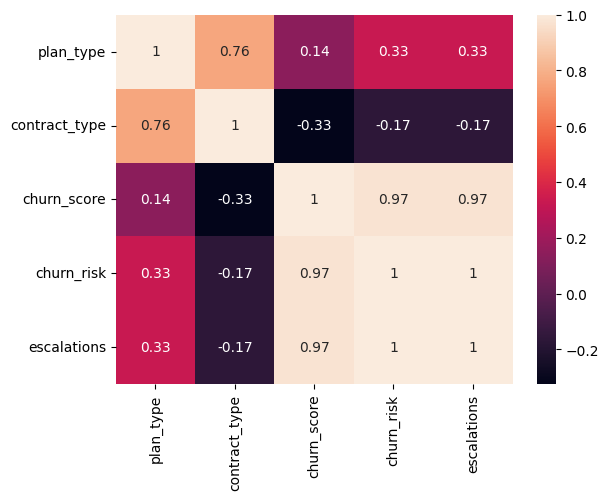

In [78]:
# Heatmap (Correlation matrix)

sns.heatmap(df_encoded.corr(), annot=True)

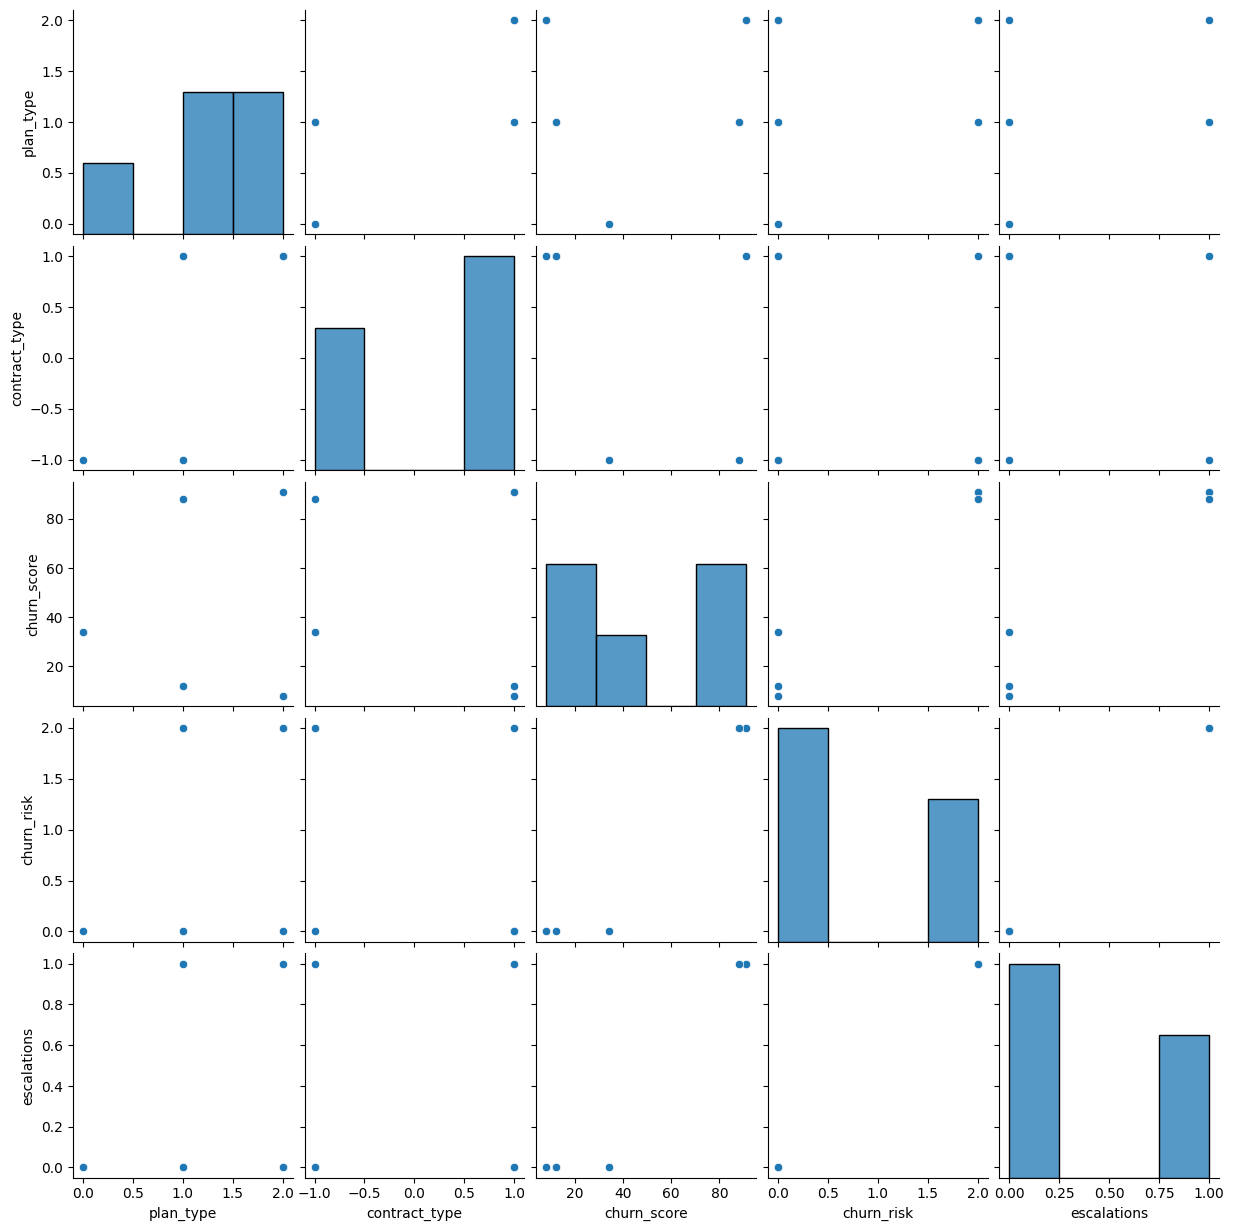

In [79]:
#Pairplot - Relation in a Dataset
sns.pairplot(df_encoded)

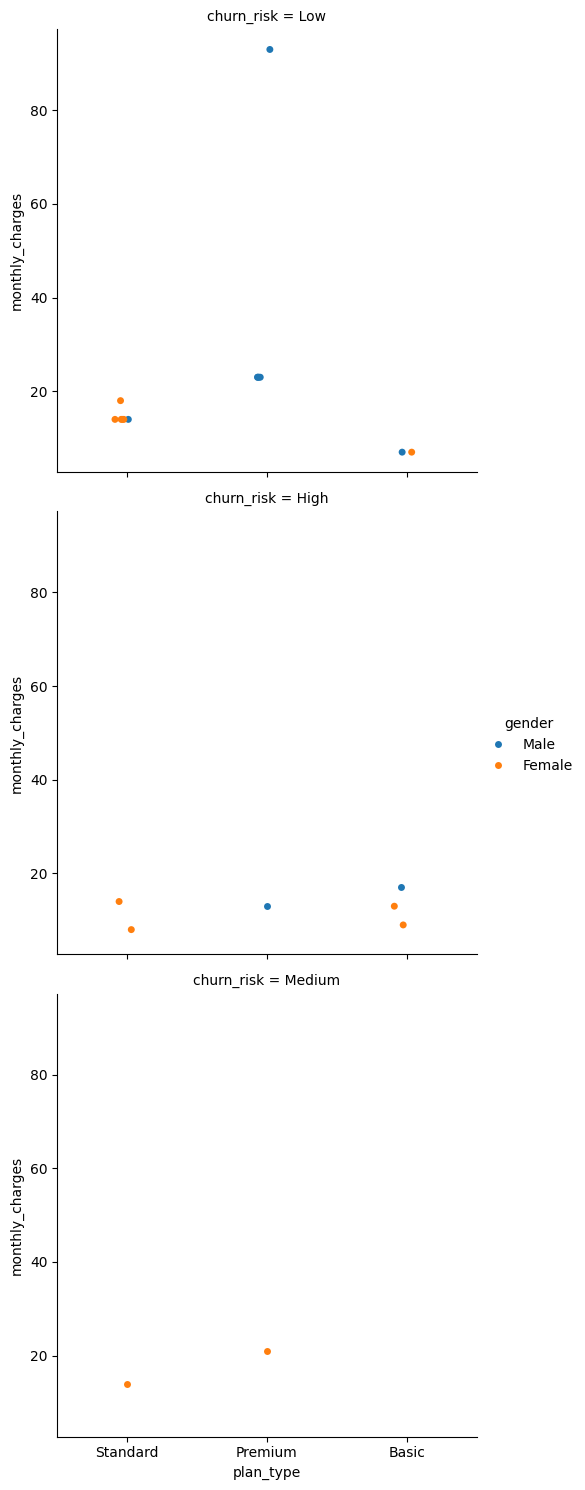

In [80]:
# Categorical/Facegrid plot - Multi-Dimension Comparision

sns.catplot(data=df_visual,
            x='plan_type',
            y='monthly_charges',
            hue='gender',
            row='churn_risk')

In [81]:
# Pivot Table

In [82]:
pd.pivot_table(
        df_visual,
        values='churn_flag',
        index='plan_type',
        aggfunc='mean'
)

,churn_flag
plan_type,
Basic,0.600000
Premium,0.142857
Standard,0.222222


In [83]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count', 'age',
       'tenure_days', 'churn_risk'],
      dtype='str')

In [85]:
pd.pivot_table(
        df_visual,
        index='plan_type',
        values=['monthly_charges', 'customerid','churn_flag'],
        aggfunc = {
            'monthly_charges' : 'sum', 
            'customerid' : 'nunique',
            'churn_flag' : 'mean'
        }
)

,churn_flag,customerid,monthly_charges
plan_type,,,
Basic,0.600000,5,52.95
Premium,0.142857,7,218.93
Standard,0.222222,9,123.91


In [86]:
# Working with SQL in Python (pandas)

In [89]:
#create db in sql
conn = sqlite3.connect('test_database.sqlite')

# table details
conn.execute("CREATE TABLE users (first_name TEXT, country TEXT, budget INTEGER)")

#commit and save
conn.commit

<function Connection.commit()>

In [91]:
#insert data

cursor = conn.cursor()

#write sql query to insert records in sql table
cursor.execute(
    """
        INSERT INTO users VALUES 
            ('Madhav','India',5000),
            ('Rishabh','Germany',2500),
            ('Vishakha','India',3500)
        
    """
)

#commit and save
conn.commit()

In [93]:
#check inserted  data in table
conn = sqlite3.connect('test_database.sqlite')
query = """SELECT * FROM users"""

df_results = pd.read_sql(query, conn)

df_results.head()

,first_name,country,budget
0,Madhav,India,5000
1,Rishabh,Germany,2500
2,Vishakha,India,3500
3,Madhav,India,5000
4,Rishabh,Germany,2500


In [96]:
# Aggregation
query = """
        SELECT country, sum(budget) as total_budget
        FROM users
        GROUP BY country
"""
df_agg = pd.read_sql(query, conn)
df_agg

,country,total_budget
0,Germany,5000
1,India,17000


In [98]:
#always close the connnection withdb once the task is done
conn.close()